# Ejercicios con Matplotlib

Cuaderno de ejercicios prácticos de visualización de datos con **Matplotlib**, **Pandas** y **Seaborn**. Completa las celdas de código correspondientes a cada enunciado.

### Configuración inicial
Ejecuta esta celda para importar las librerías principales que necesitarás a lo largo del cuaderno.

In [32]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from scipy import stats


---
## Ejercicio 1
Escribir un programa que pregunte al usuario por las ventas de un rango de años y muestre por pantalla un diagrama de líneas con la evolución de las ventas.

<function matplotlib.pyplot.show(close=None, block=None)>

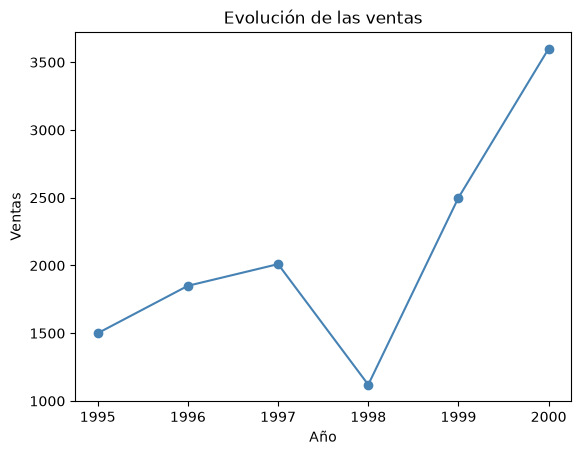

In [3]:
anyo_ini = int(input("Año de inicio"))
anyo_fin = int(input("Año de fin"))
ventas={}
for anyo in range(anyo_ini,anyo_fin + 1):
    cantidad = float(input(f"ventas del {anyo}"))
    ventas[anyo]= cantidad

fig,ax = plt.subplots()

ax.plot(ventas.keys(),ventas.values(), color="steelblue", marker="o")
ax.set_title("Evolución de las ventas")
ax.set_xlabel("Año")
ax.set_ylabel("Ventas")

plt.show

---
## Ejercicio 2
Escribir una función que reciba un diccionario con las notas de las asignaturas de un curso y una cadena con el nombre de un color y devuelva un diagrama de barras de las notas en el color dado.

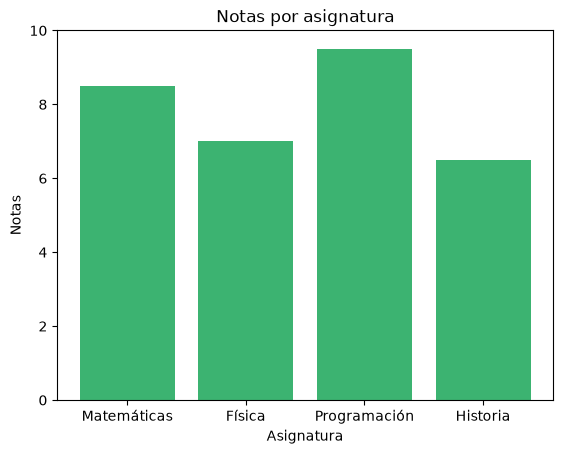

In [18]:
def diagrama_notas(notas,color):
    fig,ax = plt.subplots()

    ax.bar(notas.keys(), notas.values(), color=(f"{color}"))

    ax.set_title("Notas por asignatura")
    ax.set_xlabel("Asignatura")
    ax.set_ylabel("Notas")
    ax.set_ylim(0,10)
    return ax

mis_notas = {
    "Matemáticas": 8.5,
    "Física": 7.0,
    "Programación": 9.5,
    "Historia": 6.5
}

diagrama_notas(mis_notas, "mediumseagreen")
plt.show()

---
## Ejercicio 3
Escribir una función que reciba una serie de Pandas con las notas de los alumnos de un curso y devuelva un diagrama de cajas con las notas. El diagrama debe tener el título `"Distribución de notas"`.

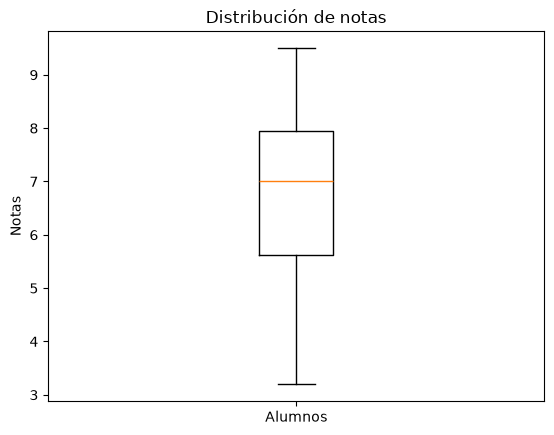

In [21]:
def diagrama_cajas_notas(serie_notas):
    fig, ax = plt.subplots()
    ax.boxplot(serie_notas)
    ax.set_title("Distribución de notas")
    ax.set_ylabel("Notas")
    ax.set_xticklabels(["Alumnos"])
    return ax

notas_alumnos = pd.Series([5.5, 6.0, 7.2, 8.1, 9.5, 4.0, 6.8, 7.5, 8.8, 3.2])
diagrama_cajas_notas(notas_alumnos)
plt.show()

---
## Ejercicio 4
El fichero `bancos.csv` contiene las cotizaciones de los principales bancos de España con:
- `Empresa` (nombre de la empresa)
- `Apertura` (precio de la acción a la apertura de bolsa)
- `Máximo` (precio máximo de la acción durante la jornada)
- `Mínimo` (precio mínimo de la acción durante la jornada)
- `Cierre` (precio de la acción al cierre de bolsa)
- `Volumen` (volumen al cierre de bolsa)

Construir una función que reciba el fichero `bancos.csv` y cree un diagrama de líneas con las series temporales de las cotizaciones de cierre de cada banco.

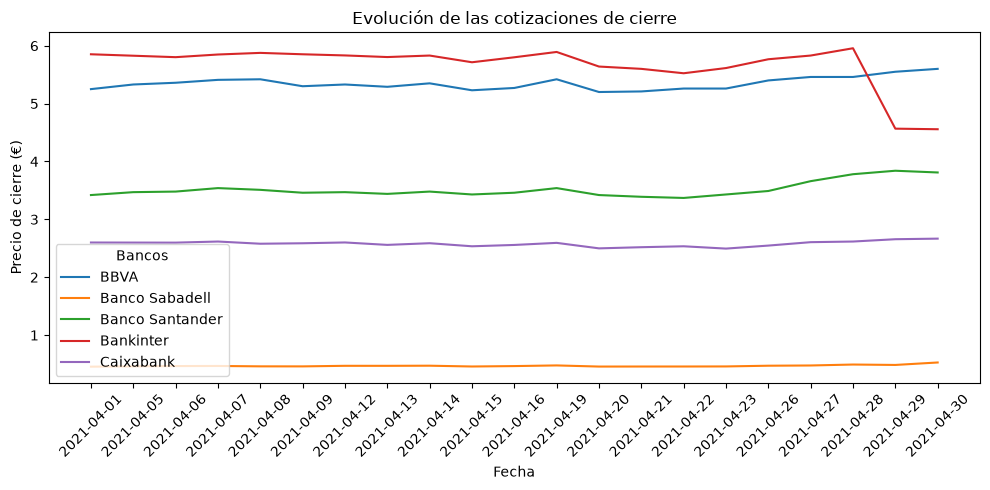

In [9]:
df_bancos = pd.read_csv('bancos.csv')

fig, ax = plt.subplots(figsize=(10, 5))
    
for empresa, datos in df_bancos.groupby('Empresa'):
    ax.plot(datos['Fecha'], datos['Cierre'], label=empresa)
        
ax.set_title("Evolución de las cotizaciones de cierre")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio de cierre (€)")
ax.legend(title="Bancos")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


---
## Ejercicio 5
El fichero `titanic.csv` contiene información sobre los pasajeros del Titanic. Crear un DataFrame con Pandas y a partir de él generar los siguientes diagramas:
1. Diagrama de sectores con los fallecidos y supervivientes.
2. Histograma con las edades.
3. Diagrama de barras con el número de personas en cada clase.
4. Diagrama de barras con el número de personas fallecidas y supervivientes en cada clase.
5. Diagrama de barras con el número de personas fallecidas y supervivientes acumuladas en cada clase.

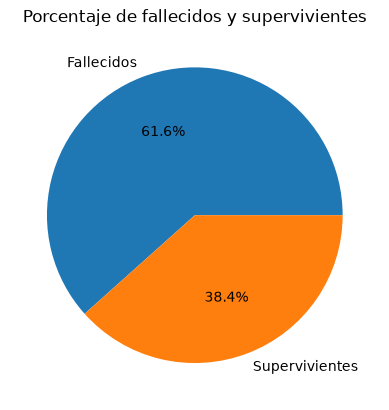

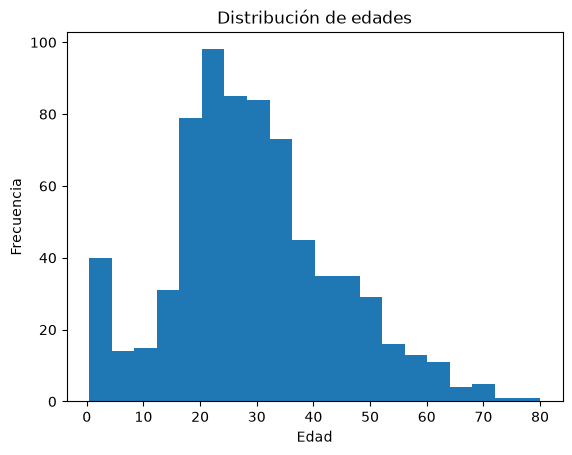

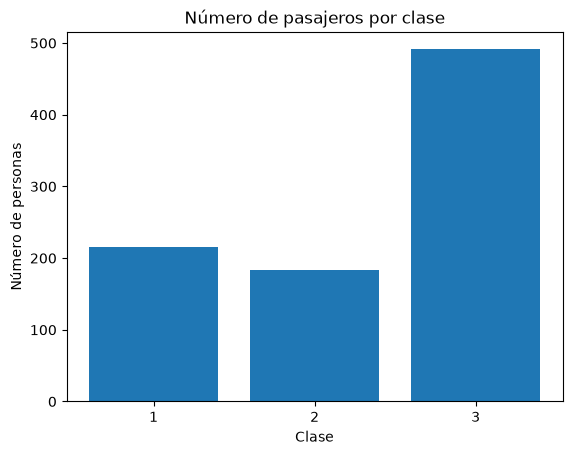

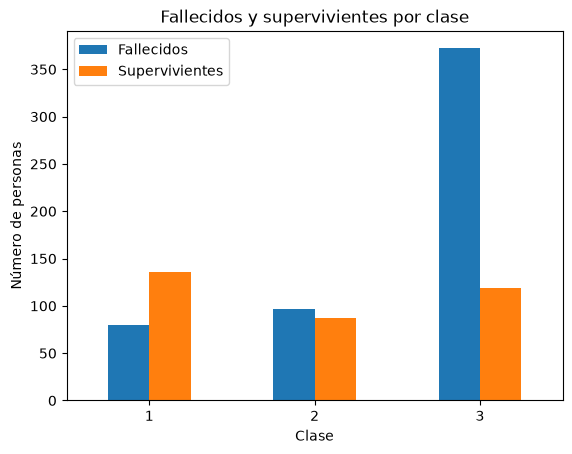

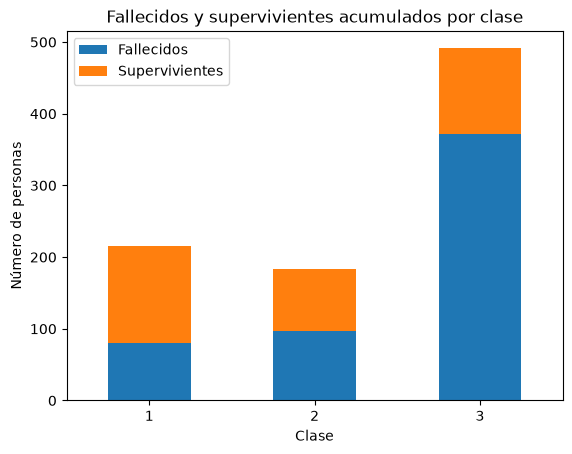

In [15]:
df_titanic = pd.read_csv('titanic.csv')

# 1. Diagrama de sectores con fallecidos y supervivientes
fig, ax = plt.subplots()
supervivientes = df_titanic['Survived'].value_counts()
ax.pie(supervivientes, labels=['Fallecidos', 'Supervivientes'], autopct='%1.1f%%')
ax.set_title("Porcentaje de fallecidos y supervivientes")
plt.show()

# 2. Histograma con las edades
fig, ax = plt.subplots()
ax.hist(df_titanic['Age'].dropna(), bins=20)
ax.set_title("Distribución de edades")
ax.set_xlabel("Edad")
ax.set_ylabel("Frecuencia")
plt.show()

# 3. Diagrama de barras con el número de personas en cada clase
fig, ax = plt.subplots()
clases = df_titanic['Pclass'].value_counts().sort_index()
ax.bar(clases.index.astype(str), clases.values)
ax.set_title("Número de pasajeros por clase")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de personas")
plt.show()

# 4. Barras agrupadas: fallecidos y supervivientes por clase
tabla_clases = pd.crosstab(df_titanic['Pclass'], df_titanic['Survived'])
tabla_clases.columns = ['Fallecidos', 'Supervivientes']
ax = tabla_clases.plot(kind='bar')
ax.set_title("Fallecidos y supervivientes por clase")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de personas")
plt.xticks(rotation=0)
plt.show()

# 5. Barras apiladas: fallecidos y supervivientes acumulados por clase
ax = tabla_clases.plot(kind='bar', stacked=True)
ax.set_title("Fallecidos y supervivientes acumulados por clase")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de personas")
plt.xticks(rotation=0)
plt.show()

---
## Ejercicios con el dataset `tips` de Seaborn
Para realizar los siguientes ejercicios, usaremos principalmente el conjunto de datos `tips` de Seaborn. Ejecuta la siguiente celda para cargar los datos:

In [16]:
# Cargar el conjunto de datos 'tips' de Seaborn
df = sns.load_dataset('tips')
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


---
## Ejercicio 6
Usando el dataset `tips` de Seaborn, crea una figura con **2 filas y 3 columnas** en la que sitúes las siguientes gráficas:
1. Un gráfico de barras que muestre el total de la cuenta (`total_bill`) por día (`day`).
2. Un gráfico de líneas que muestre la relación entre el total de la cuenta (`total_bill`) y la propina (`tip`). Muestra también con una línea la propina media.
3. Un gráfico de dispersión entre el total de la cuenta (`total_bill`) y la propina (`tip`).
4. Un gráfico circular que muestre la distribución del total de la cuenta por sexo (`sex`).
5. Un histograma para la distribución del total de la cuenta (`total_bill`).
6. Un gráfico de caja y bigotes con los valores de las propinas (`tip`) en función del día de la semana (`day`).

**Requisitos de personalización:**
- Añade títulos y etiquetas a los ejes en cada subgráfico.
- Ajusta el espacio entre los subgráficos para que no se solapen.

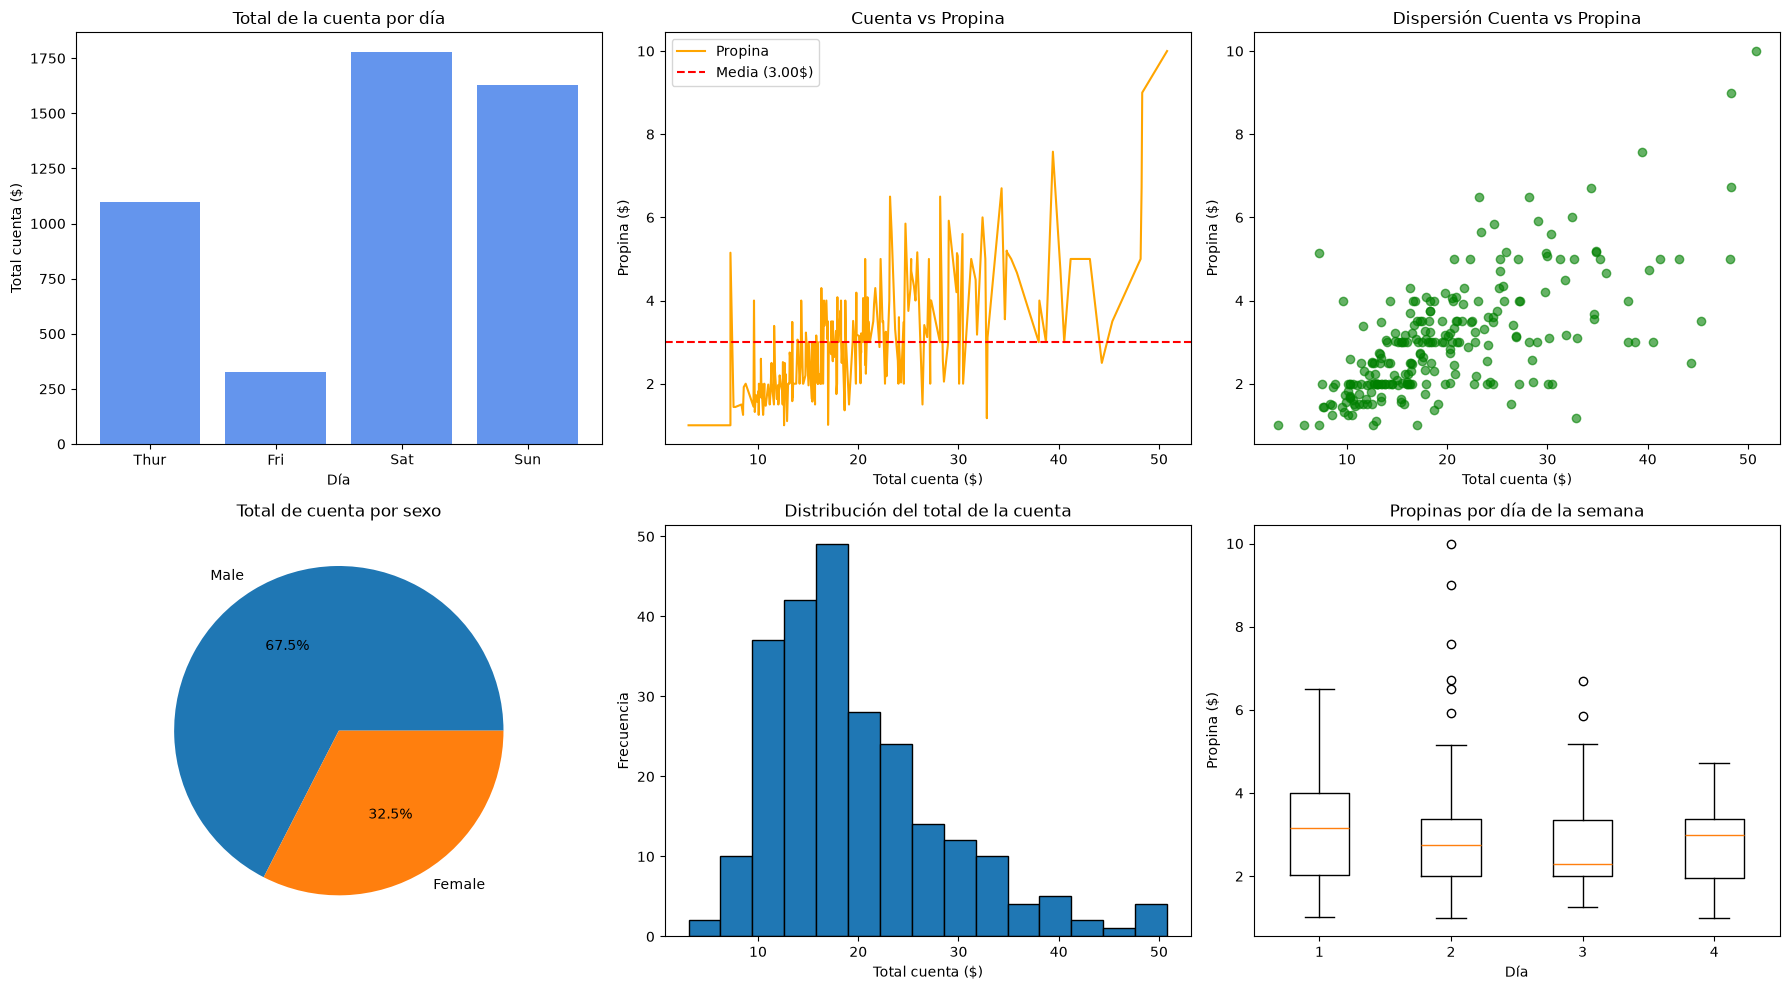

In [20]:
df = sns.load_dataset('tips')
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Barras: total de la cuenta por día
cuenta_dia = df.groupby('day', observed=False)['total_bill'].sum()
axes[0, 0].bar(cuenta_dia.index, cuenta_dia.values, color='cornflowerblue')
axes[0, 0].set_title("Total de la cuenta por día")
axes[0, 0].set_xlabel("Día")
axes[0, 0].set_ylabel("Total cuenta ($)")

# 2. Líneas: relación total_bill y tip + línea de propina media
df_ordenado = df.sort_values('total_bill')
axes[0, 1].plot(df_ordenado['total_bill'], df_ordenado['tip'], color='orange', label='Propina')
axes[0, 1].axhline(df['tip'].mean(), color='red', linestyle='--', label=f"Media ({df['tip'].mean():.2f}$)")
axes[0, 1].set_title("Cuenta vs Propina")
axes[0, 1].set_xlabel("Total cuenta ($)")
axes[0, 1].set_ylabel("Propina ($)")
axes[0, 1].legend()

# 3. Dispersión: total_bill y tip
axes[0, 2].scatter(df['total_bill'], df['tip'], alpha=0.6, color='green')
axes[0, 2].set_title("Dispersión Cuenta vs Propina")
axes[0, 2].set_xlabel("Total cuenta ($)")
axes[0, 2].set_ylabel("Propina ($)")

# 4. Circular: distribución del total de la cuenta por sexo
cuenta_sexo = df.groupby('sex', observed=False)['total_bill'].sum()
axes[1, 0].pie(cuenta_sexo.values, labels=cuenta_sexo.index, autopct='%1.1f%%',)
axes[1, 0].set_title("Total de cuenta por sexo")

# 5. Histograma: distribución de total_bill
axes[1, 1].hist(df['total_bill'], bins=15, edgecolor='black')
axes[1, 1].set_title("Distribución del total de la cuenta")
axes[1, 1].set_xlabel("Total cuenta ($)")
axes[1, 1].set_ylabel("Frecuencia")

# 6. Caja y bigotes: propinas por día de la semana
dias = df['day'].unique()
datos_cajas = [df[df['day'] == d]['tip'] for d in dias]
axes[1, 2].boxplot(datos_cajas, label=dias)
axes[1, 2].set_title("Propinas por día de la semana")
axes[1, 2].set_xlabel("Día")
axes[1, 2].set_ylabel("Propina ($)")

plt.tight_layout()
plt.show()

---
## Ejercicio 7
Usando el dataset `tips` de Seaborn, crea un gráfico de barras apiladas para mostrar cómo se distribuyen las propinas (`tip`) por día (`day`) y por sexo (`sex`).

Personaliza el gráfico añadiendo un título, etiquetas a los ejes y ajustando los colores de las barras.

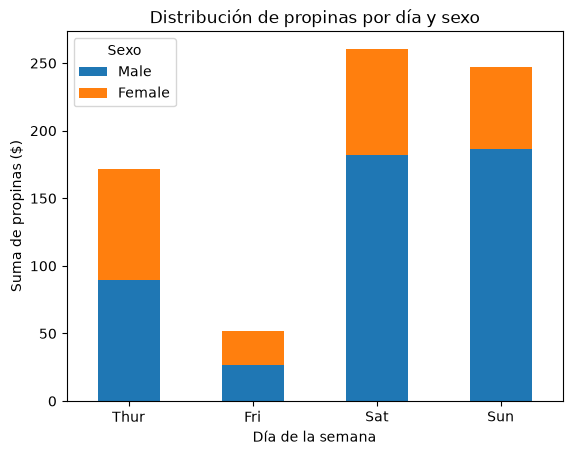

In [26]:
propinas_dia_sexo = df.pivot_table(index='day', columns='sex', values='tip', aggfunc='sum', observed=False)
ax = propinas_dia_sexo.plot(kind='bar', stacked=True)
ax.set_title("Distribución de propinas por día y sexo")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Suma de propinas ($)")
ax.legend(title="Sexo")
plt.xticks(rotation=0)
plt.show()

---
## Ejercicio 8
Usando el dataset `tips` de Seaborn, crea un gráfico de líneas en el que se representen dos series:
- La relación entre `total_bill` y `tip`.
- La relación entre `total_bill` y el tamaño de la mesa (`size`).

Añade una leyenda que identifique las dos series y personaliza el gráfico añadiendo un título y etiquetas a los ejes.

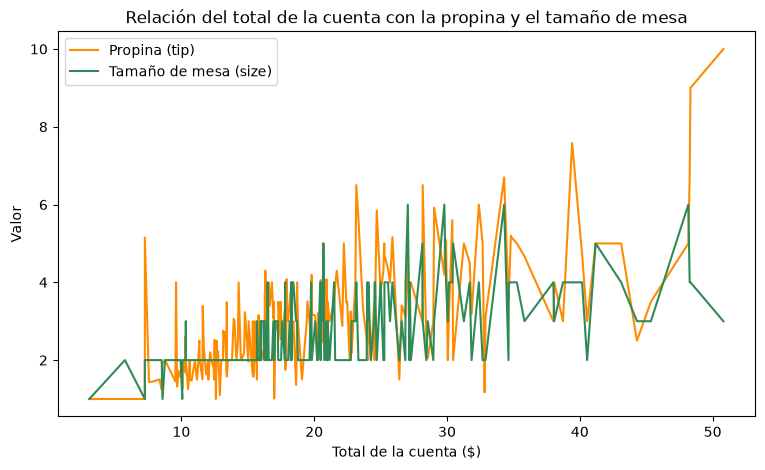

In [27]:
df_ord = df.sort_values('total_bill')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_ord['total_bill'], df_ord['tip'], label='Propina (tip)', color='darkorange')
ax.plot(df_ord['total_bill'], df_ord['size'], label='Tamaño de mesa (size)', color='seagreen')

ax.set_title("Relación del total de la cuenta con la propina y el tamaño de mesa")
ax.set_xlabel("Total de la cuenta ($)")
ax.set_ylabel("Valor")
ax.legend()
plt.show()

---
## Ejercicio 9
Usando el dataset `tips` de Seaborn, crea un gráfico de dispersión entre `total_bill` y `tip`.
- Asigna colores diferentes a los puntos del gráfico según el género (`sex`) del cliente, utilizando `color='blue'` para los hombres y `color='red'` para las mujeres.
- Personaliza el gráfico añadiendo un título, etiquetas a los ejes y una leyenda.

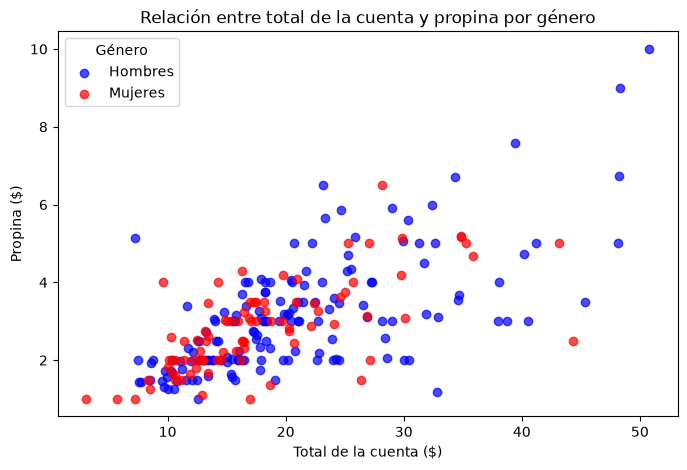

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

hombres = df[df['sex'] == 'Male']
mujeres = df[df['sex'] == 'Female']

ax.scatter(hombres['total_bill'], hombres['tip'], color='blue', label='Hombres', alpha=0.7)
ax.scatter(mujeres['total_bill'], mujeres['tip'], color='red', label='Mujeres', alpha=0.7)

ax.set_title("Relación entre total de la cuenta y propina por género")
ax.set_xlabel("Total de la cuenta ($)")
ax.set_ylabel("Propina ($)")
ax.legend(title="Género")
plt.show()

---
## Ejercicio 10
Usando el dataset `tips` de Seaborn, crea una figura con subgráficos que contengan diferentes tipos de gráficos:
- En el primer subgráfico, crea un gráfico de barras que muestre la relación entre `day` y `total_bill`.
- En el segundo subgráfico, crea un gráfico circular que muestre la distribución de `total_bill` entre los géneros (`sex`).

Personaliza ambos gráficos con títulos, etiquetas en los ejes y ajuste del espacio entre los gráficos.

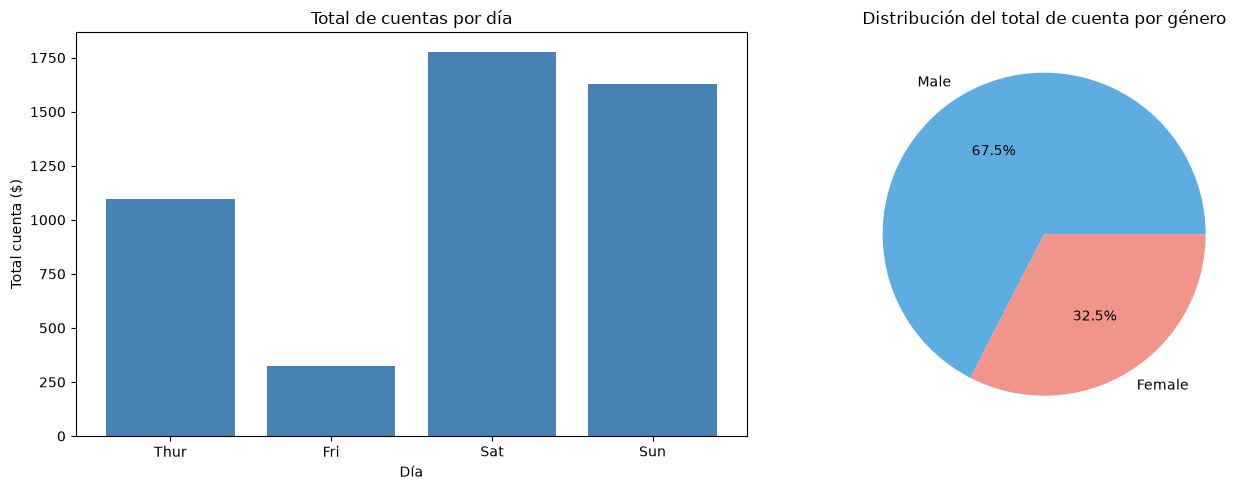

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subgráfico 1: Barras (day vs total_bill)
totales_dia = df.groupby('day', observed=False)['total_bill'].sum()
ax1.bar(totales_dia.index, totales_dia.values, color='steelblue')
ax1.set_title("Total de cuentas por día")
ax1.set_xlabel("Día")
ax1.set_ylabel("Total cuenta ($)")

# Subgráfico 2: Circular (distribución de total_bill por género)
totales_sexo = df.groupby('sex', observed=False)['total_bill'].sum()
ax2.pie(totales_sexo.values, labels=totales_sexo.index, autopct='%1.1f%%', colors=['#5dade2', '#f1948a'])
ax2.set_title("Distribución del total de cuenta por género")

plt.tight_layout()
plt.show()

---
## Ejercicio 11
Usando el dataset `tips` de Seaborn, crea un gráfico de dispersión que muestre la relación entre `total_bill` y `tip`.
- Ajusta una línea de tendencia (regresión lineal) a los datos utilizando `scipy.stats.linregress()`.
- Muestra la línea de tendencia en el gráfico junto con los puntos de dispersión.
- Personaliza el gráfico con un título, etiquetas a los ejes y una leyenda que indique la línea de tendencia.

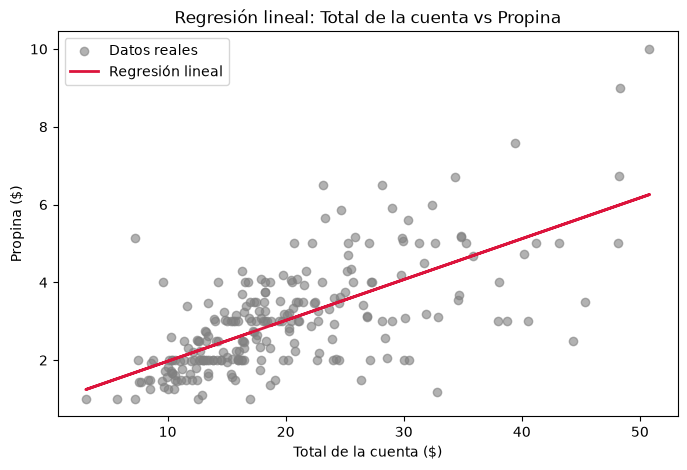

In [34]:
# Cálculo de la regresión lineal
res = stats.linregress(df['total_bill'], df['tip'])
linea_tendencia = res.intercept + res.slope * df['total_bill']

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df['total_bill'], df['tip'], color='gray', alpha=0.6, label='Datos reales')
ax.plot(df['total_bill'], linea_tendencia, color='crimson', linewidth=2, 
        label=f'Regresión lineal')

ax.set_title("Regresión lineal: Total de la cuenta vs Propina")
ax.set_xlabel("Total de la cuenta ($)")
ax.set_ylabel("Propina ($)")
ax.legend()
plt.show()